In [1]:
#Based on Aki Taanila's Tilastoapu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

plt.style.use('seaborn-whitegrid')

In [2]:
# Open the data
df = pd.read_excel('ShopSatisfactionSurveyData.xlsx')

In [ ]:
df.columns = ['H', 'gender', 'age', 'family_size', 'house', 'education', 'net_income', 'purchases', 'sat_product_range', 'sat_price_level']


In [ ]:
df.head()

## Part: Create some classification for quantitative variable

In [32]:
min(df['net_income'])

770.0

In [33]:
max(df['net_income'])

4850.0

In [34]:
bins = [500, 1000, 2000, 3000, 4000, 7000]

In [35]:
df['income_class'] = pd.cut(df['net_income'], bins = bins)

In [36]:
df

,gender,age,family_size,house,education,net_income,purchases,sat_product_range,sat_price_level,income_class
0,1,34,4,1,4,2960.0,4.0,3,2,"(2000, 3000]"
1,1,67,1,1,1,980.0,1.0,5,2,"(500, 1000]"
2,2,46,3,3,5,3500.0,4.0,2,4,"(3000, 4000]"
3,1,22,2,2,3,860.0,1.0,5,3,"(500, 1000]"
4,2,30,5,2,4,3380.0,4.0,2,3,"(3000, 4000]"
...,...,...,...,...,...,...,...,...,...,...
97,1,38,1,2,4,1380.0,1.0,4,3,"(1000, 2000]"
98,1,56,2,2,1,1700.0,2.0,3,3,"(1000, 2000]"
99,1,42,5,1,5,4430.0,5.0,2,4,"(4000, 7000]"
100,2,36,1,2,1,1100.0,1.0,5,1,"(1000, 2000]"


In [37]:
df3 = pd.crosstab(df['income_class'], 'Count')

df3.columns.name = ''

# Percentages
n = df3['Count'].sum()
df3['%'] = df3 / n * 100

In [38]:
df3

,Count,%
income_class,,
"(500, 1000]",6,6.0
"(1000, 2000]",34,34.0
"(2000, 3000]",36,36.0
"(3000, 4000]",17,17.0
"(4000, 7000]",7,7.0


In [39]:
type(df3.index.values[0])

pandas._libs.interval.Interval

In [40]:
# Note, that income column has now values of type Interval!
# We would like to add row "Total" into the index, but the Index can contain only one type of values
# for that reason we need to change the type of index elements to be string!

df3.index = df3.index.astype(str)
df3.loc['Total'] = df3.sum()
df3

,Count,%
income_class,,
"(500, 1000]",6.0,6.0
"(1000, 2000]",34.0,34.0
"(2000, 3000]",36.0,36.0
"(3000, 4000]",17.0,17.0
"(4000, 7000]",7.0,7.0
Total,100.0,100.0


In [41]:
type(df3.index.values[0])

str

In [42]:
# Finalizing the layout
df3.style.format({'Count': '{:.0f}', '%': '{:.1f} %'})

,Count,%
income_class,,
"(500, 1000]",6,6.0 %
"(1000, 2000]",34,34.0 %
"(2000, 3000]",36,36.0 %
"(3000, 4000]",17,17.0 %
"(4000, 7000]",7,7.0 %
Total,100,100.0 %


## Part: Also create Histograms using the counts and using percentages

 - let's cover the counts part first

Text(0, 0.5, 'Count, n=100')

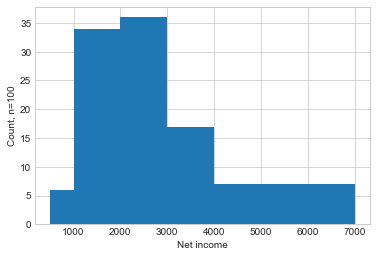

In [43]:
df['net_income'].hist(bins = bins)

plt.xlabel('Net income')
plt.ylabel('Count, n=' + str(n))

- Then let's cover percentages

Text(0, 0.5, '%, n=100')

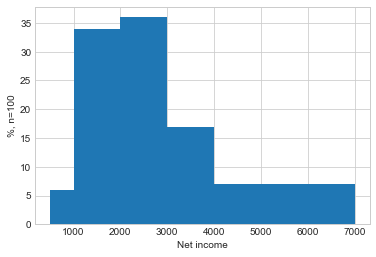

In [44]:
df['net_income'].hist(bins = bins, weights = np.ones(n) / n * 100)

plt.xlabel('Net income')
plt.ylabel('%, n=' + str(n))